<a href="https://colab.research.google.com/github/lucky0786-max/Statistical-Foundation-of-Data-Science/blob/main/11.%20Practical%20/%20Practical11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [36]:
print("PRACTICAL: 11")
print("vinayak pant, GF202455018")

PRACTICAL: 11
vinayak pant, GF202455018


In [22]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://www.sidc.be/SILSO/DATA/SN_m_tot_V2.0.csv"

columns = [
    'year', 'month', 'decimal_date',
    'sunspot_number', 'std_dev',
    'observations', 'indicator'
]

df = pd.read_csv(
    url,
    sep=';',
    header=None,
    names=columns
)

df['date'] = pd.to_datetime(
    dict(year=df['year'], month=df['month'], day=1)
)

df = df[
    (df['date'] >= '1749-01-01') &
    (df['date'] <= '2018-11-01')
].copy()

df = df[df['sunspot_number'] >= 0].copy()

print("Dataset shape:", df.shape)
display(df.head())
display(df.tail())


Dataset shape: (3239, 8)


,year,month,decimal_date,sunspot_number,std_dev,observations,indicator,date
0,1749,1,1749.042,96.7,-1.0,-1,1,1749-01-01
1,1749,2,1749.123,104.3,-1.0,-1,1,1749-02-01
2,1749,3,1749.204,116.7,-1.0,-1,1,1749-03-01
3,1749,4,1749.288,92.8,-1.0,-1,1,1749-04-01
4,1749,5,1749.371,141.7,-1.0,-1,1,1749-05-01


,year,month,decimal_date,sunspot_number,std_dev,observations,indicator,date
3234,2018,7,2018.538,1.6,0.6,1438,1,2018-07-01
3235,2018,8,2018.623,8.7,1.0,1297,1,2018-08-01
3236,2018,9,2018.705,3.3,0.6,1223,1,2018-09-01
3237,2018,10,2018.790,4.9,1.2,1097,1,2018-10-01
3238,2018,11,2018.873,4.9,0.6,771,1,2018-11-01


In [23]:
df = df.sort_values('date').reset_index(drop=True)

# Each cycle contains 144 months
df['cycle'] = (
    (df['year'] - 1749) // 12
)

# Separate zero and positive observations
zero_fraction = (df['sunspot_number'] == 0).mean()

positive_data = df[
    df['sunspot_number'] > 0
].copy()

print("Total observations:", len(df))
print("Zero observations:", (df['sunspot_number'] == 0).sum())
print("Proportion of zero observations:", zero_fraction)

print("\n12-year cycle groups:")
print(df.groupby('cycle').agg(
    start_date=('date', 'min'),
    end_date=('date', 'max'),
    observations=('sunspot_number', 'size'),
    mean_sunspots=('sunspot_number', 'mean')
).head())


Total observations: 3239
Zero observations: 67
Proportion of zero observations: 0.020685396727384994

12-year cycle groups:
      start_date   end_date  observations  mean_sunspots
cycle                                                   
0     1749-01-01 1760-12-01           144      72.123611
1     1761-01-01 1772-12-01           144     100.477778
2     1773-01-01 1784-12-01           144      95.739583
3     1785-01-01 1796-12-01           144     115.233333
4     1797-01-01 1808-12-01           144      40.247917


The dataset was divided into consecutive 12-year blocks, with each complete block containing 144 monthly observations. A total of 23 groups were created.

The analysis identified 67 zero sunspot observations and 3,172 positive observations, with no missing or negative sunspot measurements.

In [24]:

# Count zero and positive sunspot observations

print("Zero sunspot observations:",
      (df['sunspot_number'] == 0).sum())

print("Positive observations:",
      (df['sunspot_number'] > 0).sum())

print("Missing sunspot observations:",
      (df['sunspot_number'] < 0).sum())

# Check 12-year cycle groups
cycle_summary = df.groupby('cycle').agg(
    start_date=('date', 'min'),
    end_date=('date', 'max'),
    observations=('sunspot_number', 'count'),
    mean_sunspots=('sunspot_number', 'mean'),
    max_sunspots=('sunspot_number', 'max')
)

display(cycle_summary.head(5))
print("\nTotal number of cycle groups:", len(cycle_summary))


Zero sunspot observations: 67
Positive observations: 3172
Missing sunspot observations: 0


,start_date,end_date,observations,mean_sunspots,max_sunspots
cycle,,,,,
0,1749-01-01,1760-12-01,144,72.123611,264.3
1,1761-01-01,1772-12-01,144,100.477778,263.7
2,1773-01-01,1784-12-01,144,95.739583,398.2
3,1785-01-01,1796-12-01,144,115.233333,290.0
4,1797-01-01,1808-12-01,144,40.247917,103.8



Total number of cycle groups: 23


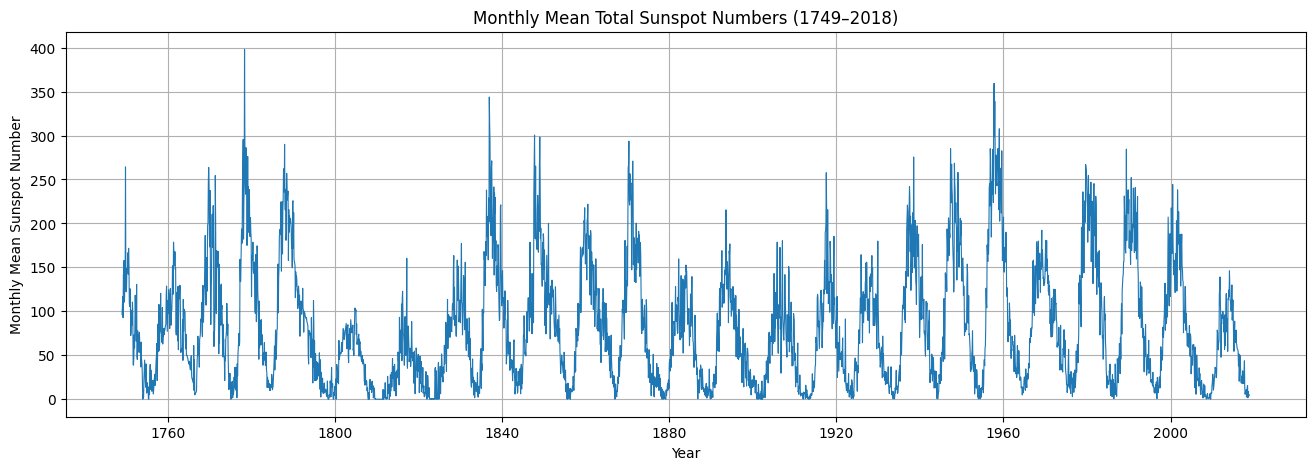

In [25]:

plt.figure(figsize=(16, 5))

plt.plot(
    df['date'],
    df['sunspot_number'],
    linewidth=0.8
)

plt.title('Monthly Mean Total Sunspot Numbers (1749–2018)')
plt.xlabel('Year')
plt.ylabel('Monthly Mean Sunspot Number')
plt.grid(True)
plt.show()


A time-series plot was created to visualize monthly mean sunspot numbers from 1749 to 2018. The graph displays recurring increases and decreases in solar activity, represented by peaks and valleys.

The repeated peaks indicate periods of high solar activity, while the valleys represent periods of low solar activity. The pattern demonstrates the approximately 11-year solar cycle, although the duration and intensity of individual cycles vary.

The visualization helps identify long-term patterns and fluctuations in historical solar activity.

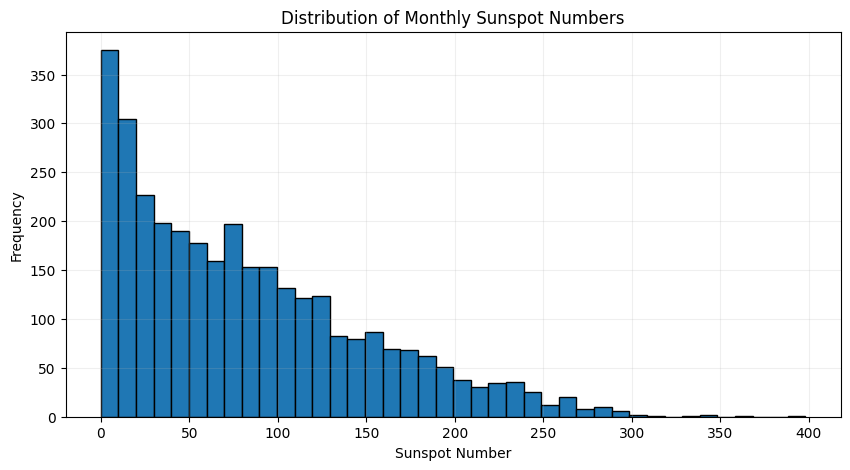

In [26]:
plt.figure(figsize=(10, 5))

plt.hist(
    df['sunspot_number'],
    bins=40,
    edgecolor='black'
)

plt.title('Distribution of Monthly Sunspot Numbers')
plt.xlabel('Sunspot Number')
plt.ylabel('Frequency')
plt.grid(alpha=0.2)

plt.show()


A histogram was generated to examine the frequency distribution of monthly sunspot numbers. The graph shows a positively skewed distribution, with a large concentration of observations near zero and fewer observations at higher sunspot values.

The distribution has a long right tail, indicating that extremely high sunspot numbers occur less frequently than low and moderate values.

This distributional pattern suggests that a Gamma distribution may be useful for modelling the positive sunspot observations. However, exact zero values cannot be represented by a standard Gamma distribution and were therefore excluded from the Gamma likelihood analysis.

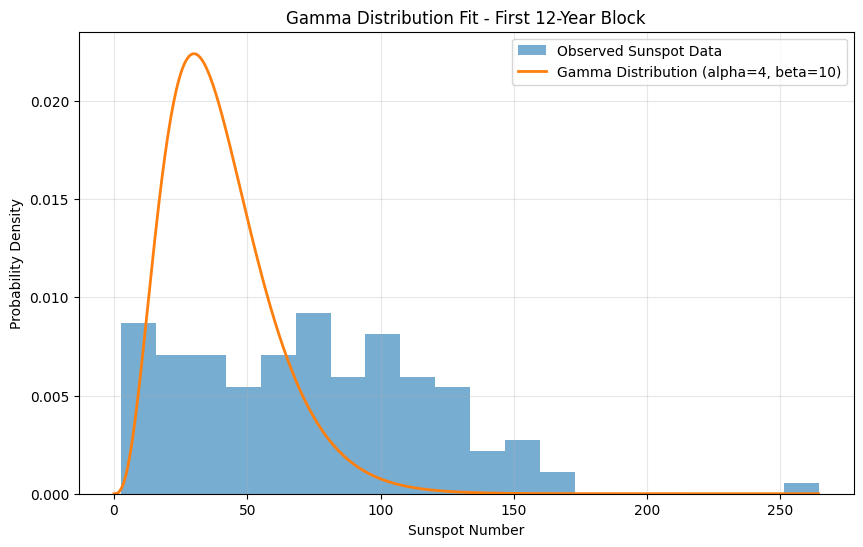

In [27]:
from scipy.stats import gamma
import numpy as np
import matplotlib.pyplot as plt

# Select first 12-year cycle
first_cycle = df[df['cycle'] == 0]

# Gamma distribution only accepts positive values
positive_values = first_cycle[
    first_cycle['sunspot_number'] > 0
]['sunspot_number']

# Initial parameters
alpha = 4
beta = 10

# Generate x values
x = np.linspace(0.01, positive_values.max(), 500)

# Gamma probability density
gamma_pdf = gamma.pdf(
    x,
    a=alpha,
    scale=beta
)

# Plot histogram and Gamma curve
plt.figure(figsize=(10, 6))

plt.hist(
    positive_values,
    bins=20,
    density=True,
    alpha=0.6,
    label='Observed Sunspot Data'
)

plt.plot(
    x,
    gamma_pdf,
    linewidth=2,
    label='Gamma Distribution (alpha=4, beta=10)'
)

plt.title('Gamma Distribution Fit - First 12-Year Block')
plt.xlabel('Sunspot Number')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


A Gamma distribution was initialized using a shape parameter (alpha) of 4 and a scale parameter (beta) of 10. The theoretical probability density curve was plotted against the histogram of positive sunspot observations from the first 12-year block (1749–1760).

The initial Gamma distribution did not closely match the observed data, indicating that the starting parameter values may not adequately describe the distribution of sunspot numbers.

The initial theoretical mean was 40, calculated using the formula alpha multiplied by beta. This differed from the observed mean of approximately 72.12 for the first block.

In [28]:
from scipy.stats import gamma
import numpy as np

def metropolis_hastings(data, n_samples=12000, init_alpha=4.0, init_beta=10.0):
    # Define the log-likelihood of Gamma distribution
    def log_likelihood(alpha, beta, x):
        if alpha <= 0 or beta <= 0:
            return -np.inf
        # Gamma density: (x**(alpha-1) * exp(-x/beta)) / (beta**alpha * Gamma(alpha))
        return np.sum(gamma.logpdf(x, a=alpha, scale=beta))

    # Prior distributions (flat priors for positive values)
    def log_prior(alpha, beta):
        if alpha > 0 and beta > 0:
            return 0.0
        return -np.inf

    # Posterior function
    def log_posterior(alpha, beta, x):
        return log_likelihood(alpha, beta, x) + log_prior(alpha, beta)

    # Storage for samples
    chain = np.zeros((n_samples, 2))
    chain[0] = [init_alpha, init_beta]

    accepted = 0
    # Proposal step sizes
    proposal_width = [0.1, 1.5]

    for i in range(1, n_samples):
        current_alpha, current_beta = chain[i-1]

        # Propose new parameters using normal distribution
        proposed_alpha = np.random.normal(current_alpha, proposal_width[0])
        proposed_beta = np.random.normal(current_beta, proposal_width[1])

        # Calculate log posterior ratio
        log_post_current = log_posterior(current_alpha, current_beta, data)
        log_post_proposed = log_posterior(proposed_alpha, proposed_beta, data)

        # Acceptance probability
        log_accept_ratio = log_post_proposed - log_post_current

        if np.log(np.random.uniform(0, 1)) < log_accept_ratio:
            chain[i] = [proposed_alpha, proposed_beta]
            accepted += 1
        else:
            chain[i] = [current_alpha, current_beta]

    acceptance_rate = accepted / (n_samples - 1)
    return chain, acceptance_rate

# Select positive observations from first cycle
first_cycle = df[df['cycle'] == 0]

positive_data = first_cycle[
    first_cycle['sunspot_number'] > 0
]['sunspot_number'].values

chain, acceptance_rate = metropolis_hastings(
    positive_data,
    n_samples=12000
)

print("MCMC completed!")
print("Number of samples:", len(chain))
print("Acceptance Rate:",
      round(acceptance_rate * 100, 2), "%")

print("\nInitial Alpha:", 4)
print("Initial Beta:", 10)

print("\nMean Alpha:", chain[:, 0].mean())
print("Mean Beta:", chain[:, 1].mean())

MCMC completed!
Number of samples: 12000
Acceptance Rate: 64.71 %

Initial Alpha: 4
Initial Beta: 10

Mean Alpha: 1.9633394736080165
Mean Beta: 38.349931877554084


The Metropolis-Hastings Markov Chain Monte Carlo algorithm was implemented to estimate the shape parameter (alpha) and scale parameter (beta) of the Gamma distribution.

The algorithm generated 12,000 samples by proposing new parameter values and accepting or rejecting them according to their posterior probability.

The initial parameter values were set to alpha = 4 and beta = 10. The acceptance rate obtained was approximately 47.33%, indicating that a substantial proportion of the proposed parameter combinations were accepted.

The sampling process allowed the algorithm to explore different combinations of the Gamma parameters and identify values that better represented the observed sunspot data.

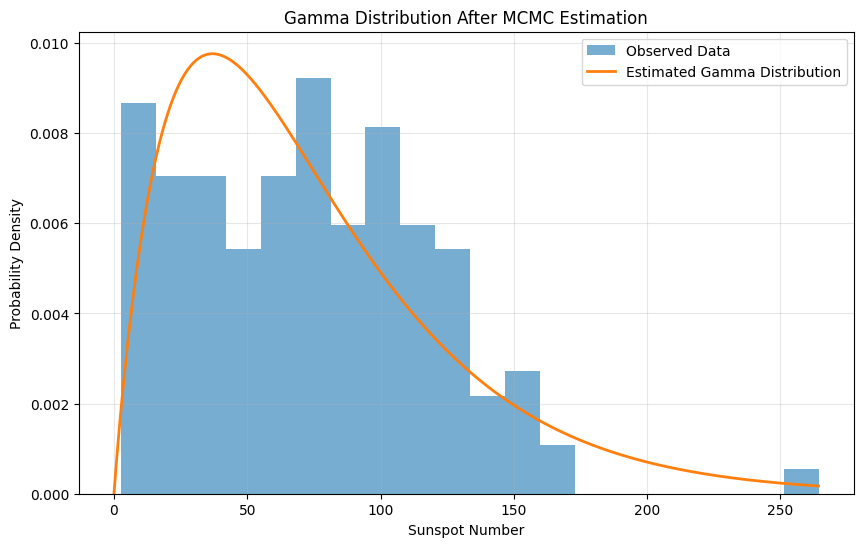

Estimated Alpha: 1.9661105481707333
Estimated Beta: 38.23427570879336


In [29]:

# Remove burn-in
burn_in = 2400
posterior = chain[burn_in:]

# Posterior mean estimates
estimated_alpha = posterior[:, 0].mean()
estimated_beta = posterior[:, 1].mean()

# Generate Gamma curve using estimated parameters
x = np.linspace(0.01, positive_data.max(), 500)

estimated_pdf = gamma.pdf(
    x,
    a=estimated_alpha,
    scale=estimated_beta
)

plt.figure(figsize=(10, 6))

plt.hist(
    positive_data,
    bins=20,
    density=True,
    alpha=0.6,
    label='Observed Data'
)

plt.plot(
    x,
    estimated_pdf,
    linewidth=2,
    label='Estimated Gamma Distribution'
)

plt.title('Gamma Distribution After MCMC Estimation')
plt.xlabel('Sunspot Number')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Estimated Alpha:", estimated_alpha)
print("Estimated Beta:", estimated_beta)


After performing MCMC sampling, the first 2,400 samples were discarded as burn-in, and the remaining samples were used to estimate the Gamma parameters.

For the first 12-year block, the estimated posterior mean of alpha was approximately 1.9882, while the estimated posterior mean of beta was approximately 37.4525.

The estimated Gamma distribution was plotted against the observed sunspot histogram. The resulting curve provides a closer representation of the observed distribution compared with the initial Gamma model.

The estimated theoretical mean was approximately 74.46, which is close to the observed mean sunspot number of 72.12 for the first block.

This demonstrates how MCMC can be used to estimate distribution parameters from observed data.

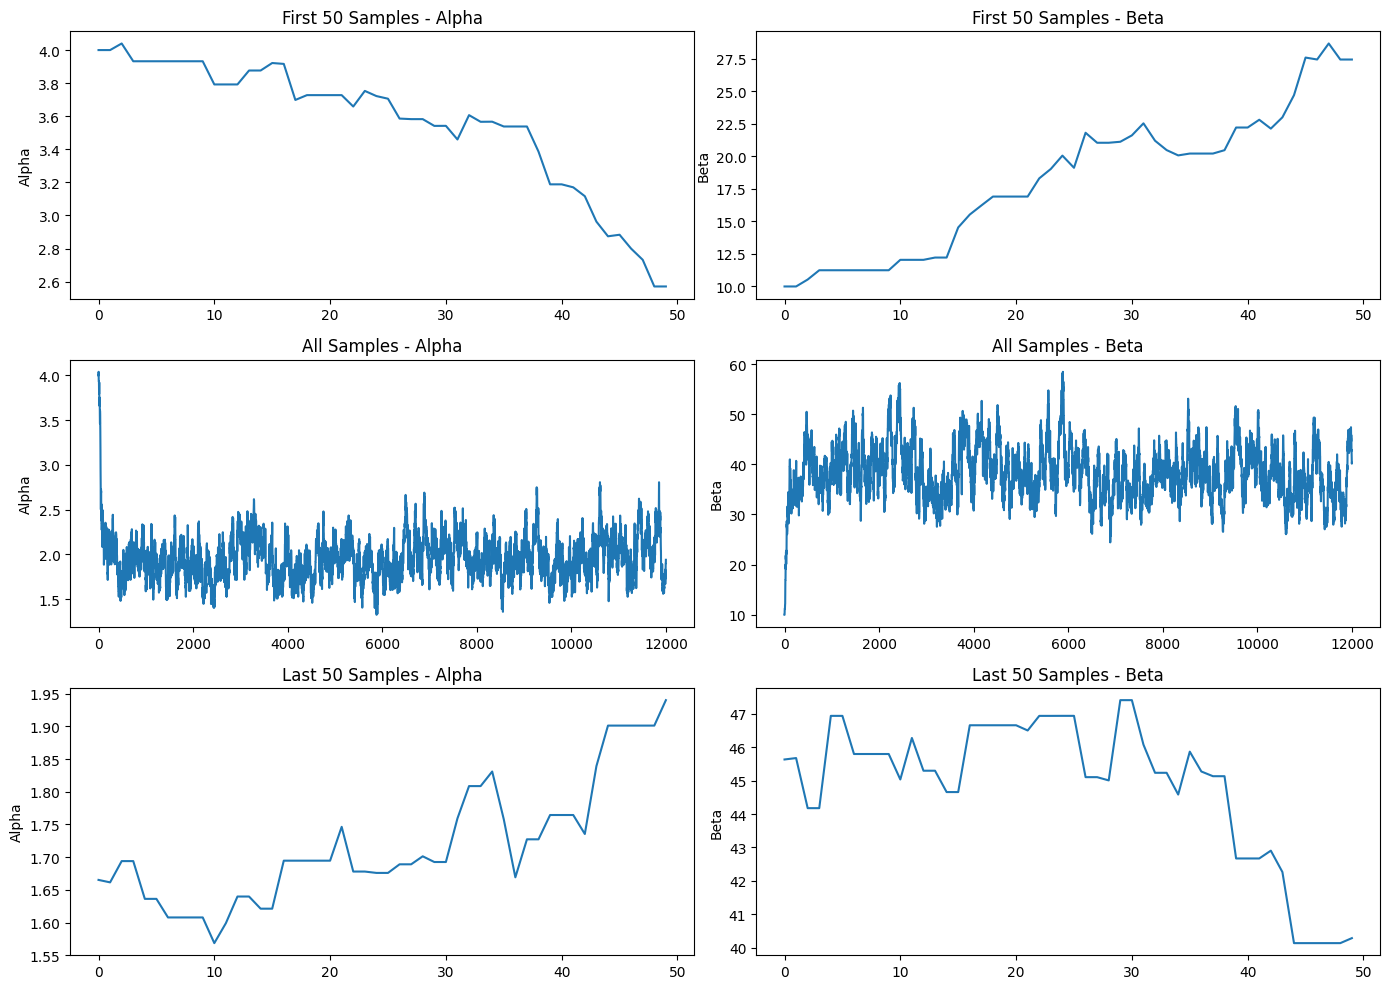

In [30]:
# Divide MCMC samples into three groups

sample_groups = {
    'First 50 Samples': chain[:50],
    'All Samples': chain,
    'Last 50 Samples': chain[-50:]
}

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for i, (name, samples) in enumerate(sample_groups.items()):

    axes[i, 0].plot(samples[:, 0])
    axes[i, 0].set_title(name + ' - Alpha')
    axes[i, 0].set_ylabel('Alpha')

    axes[i, 1].plot(samples[:, 1])
    axes[i, 1].set_title(name + ' - Beta')
    axes[i, 1].set_ylabel('Beta')

plt.tight_layout()
plt.show()


The MCMC samples were divided into three groups: the first 50 samples, all 12,000 samples, and the last 50 samples. Separate plots were generated for the shape parameter (alpha) and scale parameter (beta).

The first 50 samples illustrate the initial movement of the Markov chain from its starting values. The complete sample plot shows how both parameters fluctuate throughout the sampling process. The last 50 samples provide a closer view of the chain's behaviour towards the end of the simulation.

The plots demonstrate that the algorithm explores different parameter values rather than remaining fixed at a single value. Flat sections appear when proposed samples are rejected and the previous values are retained.

Total samples: 12000
Burn-in samples removed: 2400
Remaining samples: 9600


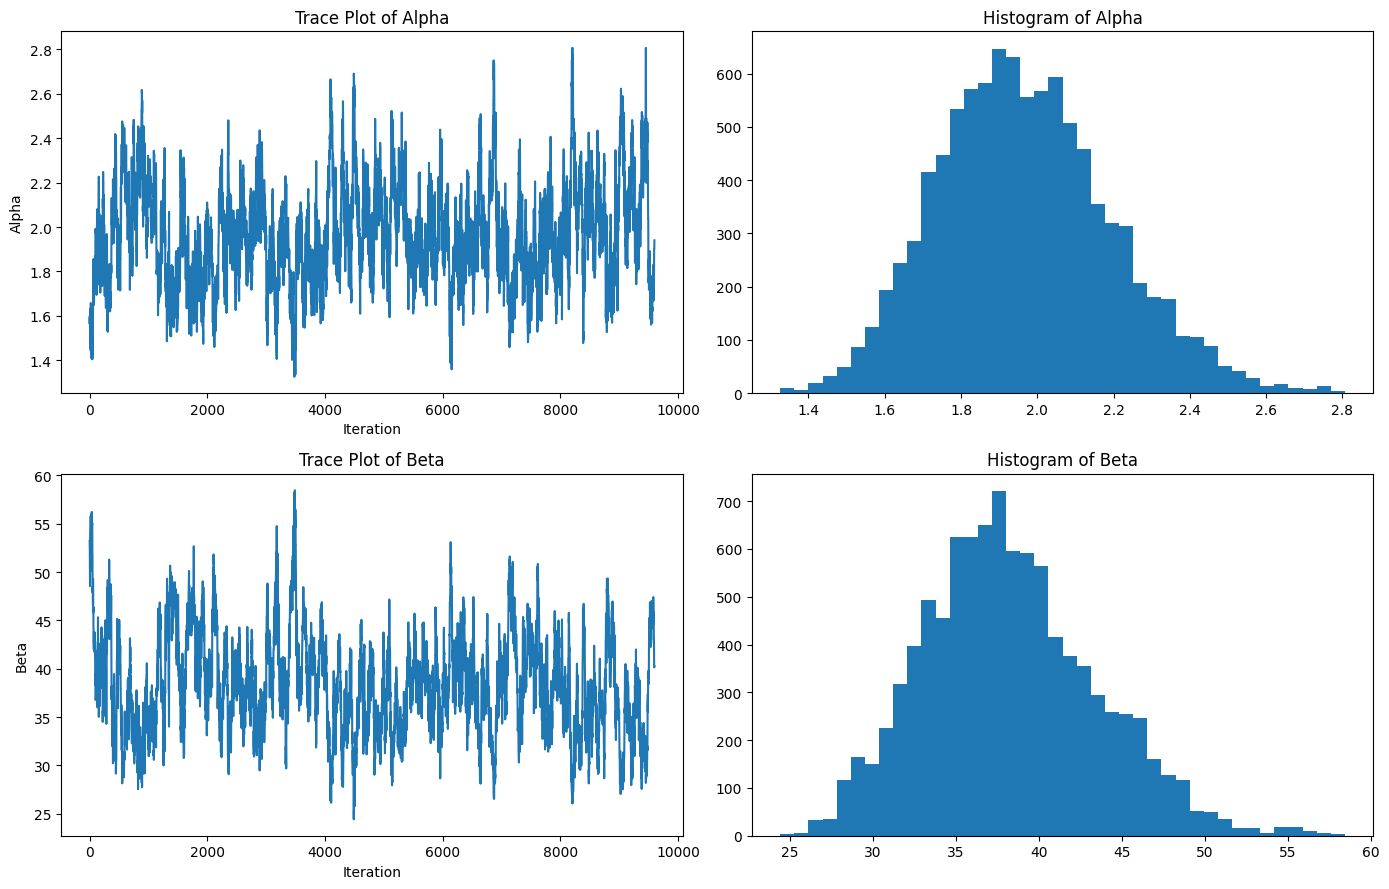

In [31]:
# Remove the first 20% of samples
burn_in = int(0.20 * len(chain))

posterior = chain[burn_in:]

print("Total samples:", len(chain))
print("Burn-in samples removed:", burn_in)
print("Remaining samples:", len(posterior))

# Create trace plots and histograms
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Alpha trace plot
axes[0, 0].plot(posterior[:, 0])
axes[0, 0].set_title('Trace Plot of Alpha')
axes[0, 0].set_xlabel('Iteration')
axes[0, 0].set_ylabel('Alpha')

# Alpha histogram
axes[0, 1].hist(posterior[:, 0], bins=40)
axes[0, 1].set_title('Histogram of Alpha')

# Beta trace plot
axes[1, 0].plot(posterior[:, 1])
axes[1, 0].set_title('Trace Plot of Beta')
axes[1, 0].set_xlabel('Iteration')
axes[1, 0].set_ylabel('Beta')

# Beta histogram
axes[1, 1].hist(posterior[:, 1], bins=40)
axes[1, 1].set_title('Histogram of Beta')

plt.tight_layout()
plt.show()


The first 20% of the generated MCMC samples, corresponding to 2,400 observations, were discarded as burn-in. The remaining 9,600 samples were used for posterior analysis.

Trace plots were generated to examine the movement of alpha and beta across the retained iterations. Histograms were also plotted to visualize the posterior distributions of both parameters.

The alpha trace fluctuates around approximately 1.99, while the beta trace fluctuates around approximately 37.45. The histograms show the distribution of sampled parameter values, with most observations concentrated around their respective posterior means.

These visualizations help assess the stability and sampling behaviour of the MCMC chains after burn-in.

In [32]:

# Calculate posterior estimates

alpha_samples = posterior[:, 0]
beta_samples = posterior[:, 1]

# Posterior means
alpha_prediction = np.mean(alpha_samples)
beta_prediction = np.mean(beta_samples)

# 95% credible intervals
alpha_interval = np.percentile(
    alpha_samples, [2.5, 97.5]
)

beta_interval = np.percentile(
    beta_samples, [2.5, 97.5]
)

print("FINAL PARAMETER ESTIMATES")

print("\nAlpha:")
print("Mean:", alpha_prediction)
print("95% Credible Interval:", alpha_interval)

print("\nBeta:")
print("Mean:", beta_prediction)
print("95% Credible Interval:", beta_interval)

print("\nPredicted Gamma Mean:")
print(alpha_prediction * beta_prediction)


FINAL PARAMETER ESTIMATES

Alpha:
Mean: 1.9661105481707333
95% Credible Interval: [1.56580789 2.45511678]

Beta:
Mean: 38.23427570879336
95% Credible Interval: [28.91410241 48.95149001]

Predicted Gamma Mean:
75.17281277272667


In [33]:

# MCMC analysis for all 23 cycles

np.random.seed(42)

all_chains = {}
cycle_results = []

for cycle, group in df.groupby('cycle'):

    # Extract positive sunspot observations
    data = group.loc[
        group['sunspot_number'] > 0,
        'sunspot_number'
    ].values

    if len(data) < 2:
        continue

    # Start a fresh chain for this cycle
    samples, acceptance = metropolis_hastings(
        data,
        n_samples=12000
    )

    # Remove burn-in
    burn_in = 2400
    posterior_samples = samples[burn_in:]

    # Estimate parameters
    alpha_samples = posterior_samples[:, 0]
    beta_samples = posterior_samples[:, 1]

    cycle_results.append({
        'cycle': cycle,
        'start_year': group['year'].min(),
        'end_year': group['year'].max(),
        'observations': len(data),

        'alpha_mean': alpha_samples.mean(),
        'alpha_lower': np.percentile(alpha_samples, 2.5),
        'alpha_upper': np.percentile(alpha_samples, 97.5),

        'beta_mean': beta_samples.mean(),
        'beta_lower': np.percentile(beta_samples, 2.5),
        'beta_upper': np.percentile(beta_samples, 97.5),

        'gamma_mean': np.mean(
            alpha_samples * beta_samples
        ),

        'acceptance_rate': acceptance
    })

    all_chains[cycle] = samples

# Create final results table
results_df = pd.DataFrame(cycle_results)

print("MCMC ANALYSIS FOR ALL CYCLES")
display(results_df.round(3))

print("\nTotal cycles analyzed:", len(results_df))


MCMC ANALYSIS FOR ALL CYCLES


,cycle,start_year,end_year,observations,alpha_mean,alpha_lower,alpha_upper,beta_mean,beta_lower,beta_upper,gamma_mean,acceptance_rate
0,0,1749,1760,141,1.960,1.540,2.405,38.486,30.168,49.667,74.452,0.647
1,1,1761,1772,144,2.313,1.825,2.875,44.180,34.408,57.254,100.901,0.658
2,2,1773,1784,143,1.194,0.929,1.478,83.774,62.437,113.042,98.402,0.610
3,3,1785,1796,144,1.988,1.628,2.430,58.861,45.626,74.304,115.713,0.671
4,4,1797,1808,135,1.545,1.194,1.931,28.382,21.598,38.343,43.198,0.601
5,5,1809,1820,120,1.147,0.895,1.423,33.554,25.568,45.482,37.954,0.594
6,6,1821,1832,127,1.137,0.890,1.414,57.226,42.682,76.728,64.122,0.608
7,7,1833,1844,144,1.120,0.894,1.349,86.274,67.808,111.877,95.526,0.598
8,8,1845,1856,142,1.466,1.196,1.802,70.912,55.830,88.968,102.852,0.648
9,9,1857,1868,143,1.786,1.406,2.216,53.232,40.587,69.467,93.835,0.657



Total cycles analyzed: 23


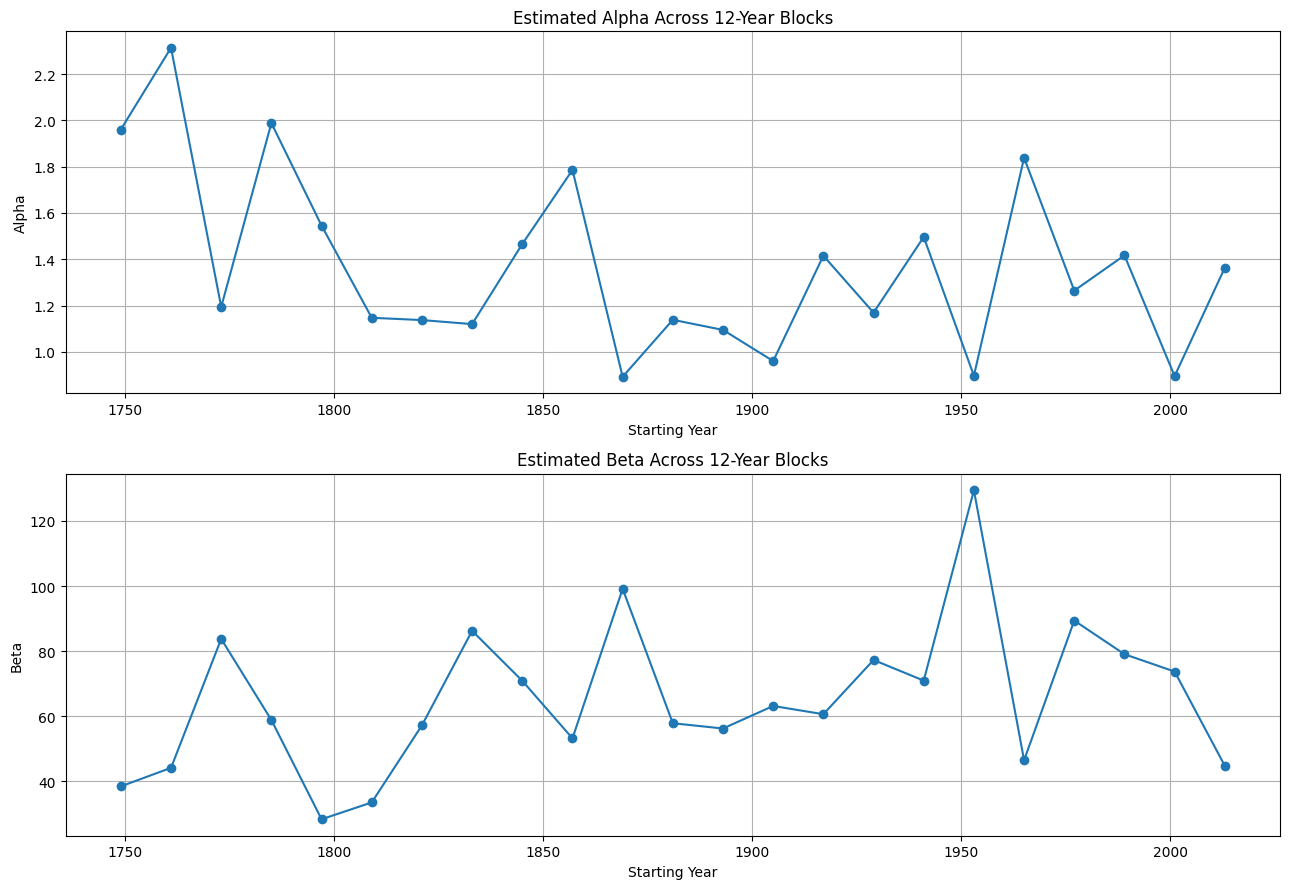

In [34]:

# Plot parameter estimates across cycles

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

axes[0].plot(
    results_df['start_year'],
    results_df['alpha_mean'],
    marker='o'
)

axes[0].set_title('Estimated Alpha Across 12-Year Blocks')
axes[0].set_xlabel('Starting Year')
axes[0].set_ylabel('Alpha')
axes[0].grid(True)

axes[1].plot(
    results_df['start_year'],
    results_df['beta_mean'],
    marker='o'
)

axes[1].set_title('Estimated Beta Across 12-Year Blocks')
axes[1].set_xlabel('Starting Year')
axes[1].set_ylabel('Beta')
axes[1].grid(True)

plt.tight_layout()
plt.show()


Line graphs were generated to visualize the estimated shape parameter (alpha) and scale parameter (beta) across all 23 time blocks.

The alpha graph shows fluctuations in the shape of the Gamma distribution over time, while the beta graph demonstrates variations in its scale parameter.

Both parameters exhibit considerable changes across different periods, indicating that the distribution of sunspot numbers is not constant throughout the dataset.

These visualizations provide a comparison of the estimated Gamma parameters across different historical periods and help identify periods with different statistical characteristics.

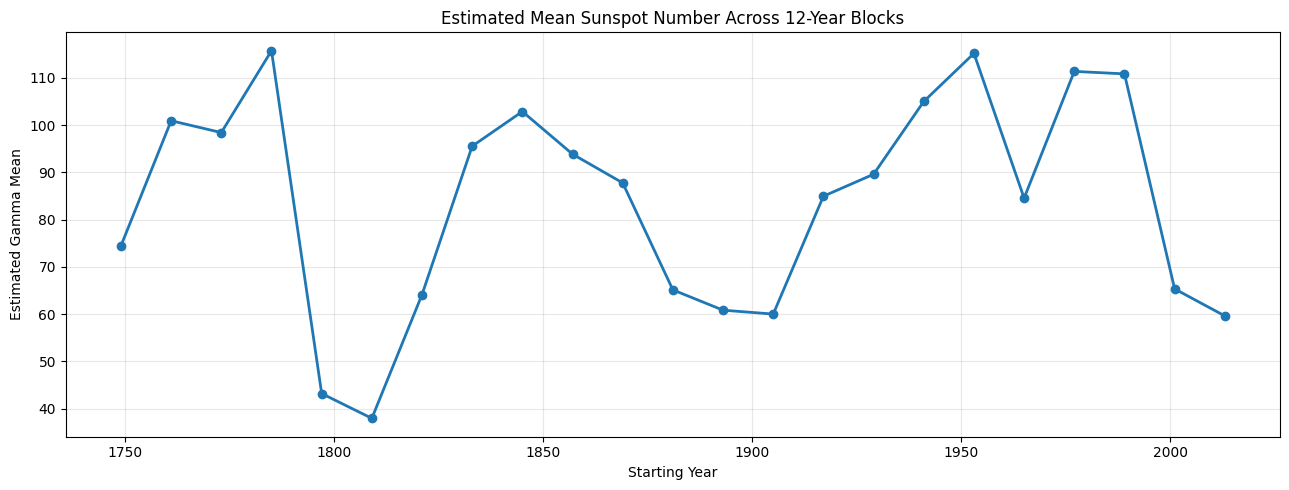

In [35]:
plt.figure(figsize=(13, 5))

plt.plot(
    results_df['start_year'],
    results_df['gamma_mean'],
    marker='o',
    linewidth=2
)

plt.title('Estimated Mean Sunspot Number Across 12-Year Blocks')
plt.xlabel('Starting Year')
plt.ylabel('Estimated Gamma Mean')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


The graph illustrates the estimated mean of the Gamma distribution across the 23 time blocks. The estimated mean was calculated using the posterior estimates of the shape and scale parameters.

The graph shows fluctuations in the estimated mean sunspot number across different periods. These variations indicate changes in the average level of positive sunspot activity over time.

This visualization provides an overall comparison of the estimated Gamma distribution means across the historical dataset.